In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error,r2_score,root_mean_squared_error

In [2]:
housing=fetch_california_housing()
data=pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)
data["MedHouseVal"]=housing.target
print(data.head())
print(data.info())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 no

In [ ]:
#Model 1
x1=data[["MedInc"]].values


In [4]:
#Model 2
x2=data[["MedInc", "AveRooms", "HouseAge"]]

In [5]:
y=data["MedHouseVal"]

In [16]:
#Split :Model 1
x_train1,x_test1,y_train,y_test=train_test_split(
    x1,y,random_state=42,test_size=0.2
)

#split: Model 2
x_train2,x_test2,y_train2,y_test2=train_test_split(
    x2,y,random_state=42,test_size=0.2
)


In [17]:
print("Training data of Model 1",len(x_train1))
print("Testing data of model 1",len(x_test1))

print("Training data of Model 2",len(x_train2))
print("Testing data of Model 2", len(x_test2))

Training data of Model 1 16512
Testing data of model 1 4128
Training data of Model 2 16512
Testing data of Model 2 4128


In [18]:
from sklearn.linear_model import LinearRegression

model1=LinearRegression()
model1.fit(x_train1,y_train)
y_pred1=model1.predict(x_test1)

mse1=mean_squared_error(y_test,y_pred1)
r2_1=r2_score(y_test,y_pred1)
rmse1=root_mean_squared_error(y_test,y_pred1)

print("\nModel 1: MedInc Only")
print("-" * 40)
print("MSE:",mse1)
print("r2_score:",r2_1)
print("RSME:",rmse1)


Model 1: MedInc Only
----------------------------------------
MSE: 0.7091157771765548
r2_score: 0.45885918903846656
RSME: 0.8420901241414454


In [21]:
model2=LinearRegression()
model2.fit(x_train2,y_train)
y_pred2=model2.predict(x_test2)

mse2=mean_squared_error(y_test2,y_pred2)
r2_2=r2_score(y_test2,y_pred2)
rmse2=root_mean_squared_error(y_test2,y_pred2)

print("\nModel 2: MedInc, AveRooms and HouseAge")
print("-" * 40)
print("MSE:", mse2)
print("RMSE:", rmse2)
print("R2 Score:", r2_2)



Model 2: MedInc, AveRooms and HouseAge
----------------------------------------
MSE: 0.6589108649336336
RMSE: 0.8117332473994358
R2 Score: 0.49717158850807075


In [22]:
comparison=pd.DataFrame({
    "Metric": ["MSE", "RMSE", "R2 Score"],
    "Model 1 (MedInc)": [mse1, rmse1, r2_1],
    "Model 2 (Multiple Features)": [mse2, rmse2, r2_2]
})
print(comparison.round(4))

     Metric  Model 1 (MedInc)  Model 2 (Multiple Features)
0       MSE            0.7091                       0.6589
1      RMSE            0.8421                       0.8117
2  R2 Score            0.4589                       0.4972


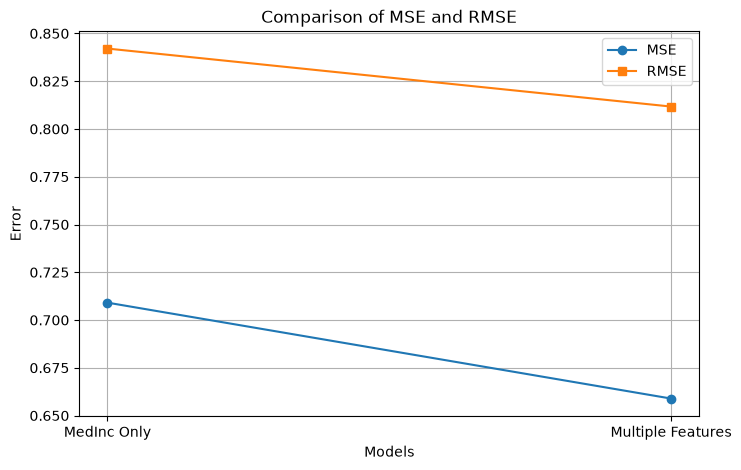

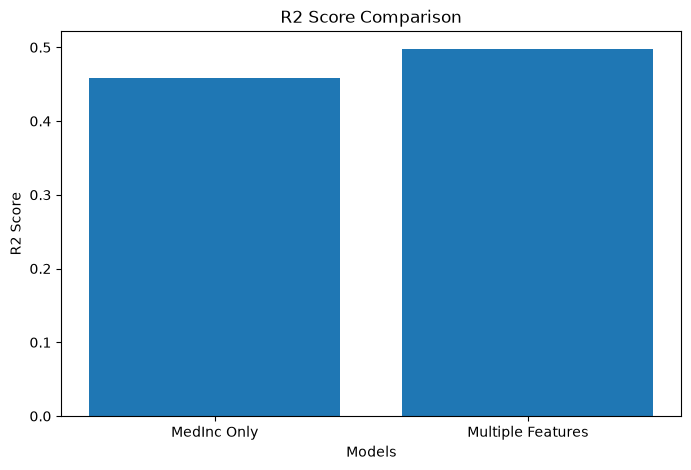

Adding multiple features improved prediction performance.


In [23]:
#compare MSE AND RMSE
models = ["MedInc Only", "Multiple Features"]

mse_values=[mse1,mse2]
r2_values=[r2_1,r2_2]
rmse_values = [rmse1, rmse2]

plt.figure(figsize=(8, 5))

plt.plot(models, mse_values, marker="o", label="MSE")
plt.plot(models, rmse_values, marker="s", label="RMSE")

plt.title("Comparison of MSE and RMSE")
plt.xlabel("Models")
plt.ylabel("Error")
plt.legend()
plt.grid(True)
plt.show()


# 11. Compare R2 Score

r2_values = [r2_1, r2_2]

plt.figure(figsize=(8, 5))

plt.bar(models, r2_values)

plt.title("R2 Score Comparison")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.show()


# 12. Conclusion

if mse2 < mse1 and r2_2 > r2_1:
    print("Adding multiple features improved prediction performance.")
else:
    print("Adding multiple features did not improve both metrics.")
